# Lab 3 – Part A: Credit Card Fraud Detection (Logistic Regression)

**Name:** Sultan Akinola Atanda | **Student ID:** 9114837

Transactions by European cardholders over two days in 2013. `V1`–`V28` are PCA components (hidden for privacy), plus `Time`, `Amount` and the target `Class` (1 = fraud). The goal is to build a logistic regression model that detects fraud, using a 70/30 train/test split.

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score)

pio.renderers.default = "plotly_mimetype+notebook_connected"
pio.templates.default = "plotly_white"
FRAUD, LEGIT = "#e63946", "#1d3557"
RANDOM_STATE = 42

## A1. Load and check the data

In [2]:
cc = pd.read_csv("creditcard.csv")
print("Shape:", cc.shape)
print("Missing values:", cc.isna().sum().sum())
print("Duplicate rows:", cc.duplicated().sum())
cc.head()

Shape: (284807, 31)
Missing values: 0
Duplicate rows: 1081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


284,807 rows, all numeric, no missing values, but **1,081 duplicates**. Duplicates can end up in both train and test and inflate the score, so they are removed.

In [3]:
cc = cc.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", cc.shape)
cc[["Time", "Amount"]].describe().round(2)

Shape after removing duplicates: (283726, 31)


,Time,Amount
count,283726.00,283726.00
mean,94811.08,88.47
std,47481.05,250.40
min,0.00,0.00
25%,54204.75,5.60
50%,84692.50,22.00
75%,139298.00,77.51
max,172792.00,25691.16


`Amount` is very skewed (median 22, max 25,691) and both `Time` and `Amount` are on a much larger scale than the PCA features, so they will be standardised.

## A2. Exploratory analysis

             count  percent
Class                      
Legitimate  283253    99.83
Fraud          473     0.17


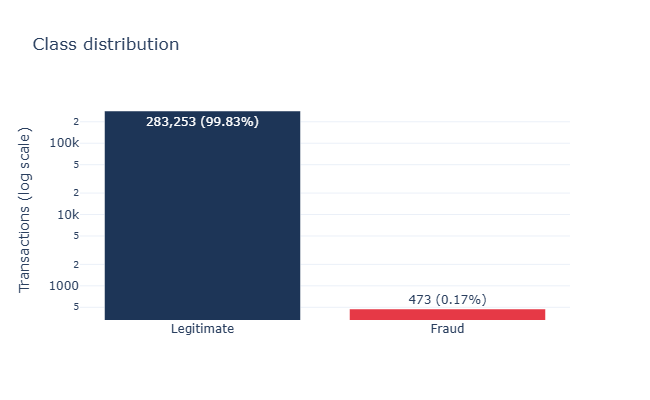

In [4]:
counts = cc["Class"].value_counts().rename({0: "Legitimate", 1: "Fraud"})
pct = (counts / counts.sum() * 100).round(2)
print(pd.DataFrame({"count": counts, "percent": pct}))

fig = px.bar(x=counts.index, y=counts.values, color=counts.index, log_y=True,
             text=[f"{c:,} ({p}%)" for c, p in zip(counts, pct)],
             color_discrete_map={"Legitimate": LEGIT, "Fraud": FRAUD},
             labels={"x": "", "y": "Transactions (log scale)"}, title="Class distribution")
fig.update_layout(showlegend=False, height=400)
fig.show()

Only **0.17%** of transactions are fraud (473 of 283,726). A model that always says "legitimate" would already be 99.83% accurate, so accuracy alone is misleading here. I use a **stratified** split and also look at precision and recall.

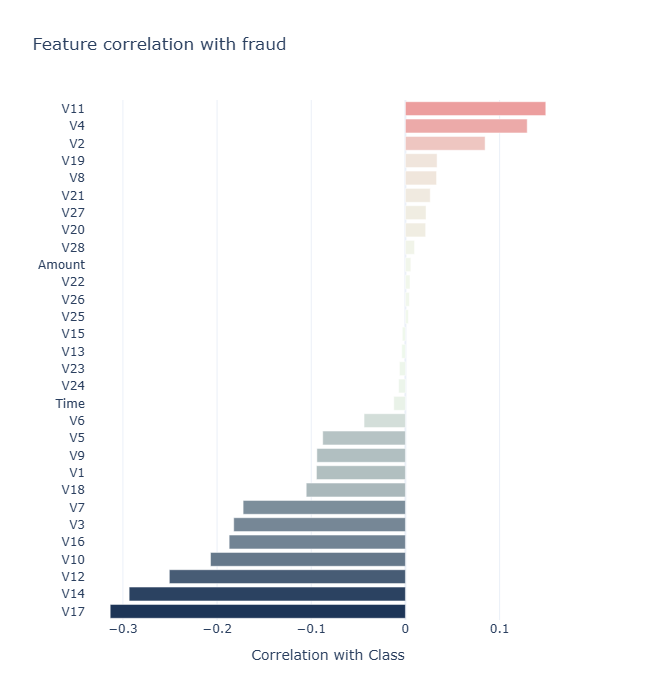

In [5]:
corr = cc.corr()["Class"].drop("Class").sort_values()
fig = px.bar(x=corr.values, y=corr.index, orientation="h", color=corr.values,
             color_continuous_scale=[LEGIT, "#f1faee", FRAUD], color_continuous_midpoint=0,
             labels={"x": "Correlation with Class", "y": ""}, title="Feature correlation with fraud")
fig.update_layout(height=700, coloraxis_showscale=False)
fig.show()

`V17`, `V14`, `V12` and `V10` have the strongest (negative) relationship with fraud, and `V11` and `V4` the strongest positive one. Several features clearly carry signal, which suits a linear model like logistic regression.

## A3. Preprocessing and 70/30 split

The scaler is fit on the training set only so no test information leaks into training.

In [6]:
X = cc.drop(columns="Class")
y = cc["Class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

scaler = StandardScaler()
X_train[["Time", "Amount"]] = scaler.fit_transform(X_train[["Time", "Amount"]])
X_test[["Time", "Amount"]] = scaler.transform(X_test[["Time", "Amount"]])

print("Train:", X_train.shape, "| fraud:", y_train.sum())
print("Test: ", X_test.shape, "| fraud:", y_test.sum())

Train: (198608, 30) | fraud: 331
Test:  (85118, 30) | fraud: 142


198,608 training rows and 85,118 test rows, with the fraud rate kept the same in both (331 and 142 cases).

## A4. Train and evaluate the model

Train accuracy: 99.9240%
Test accuracy:  99.9107%
Baseline (always legit): 99.8332%
ROC-AUC: 0.9650

              precision    recall  f1-score   support

  Legitimate     0.9993    0.9998    0.9996     84976
       Fraud     0.8438    0.5704    0.6807       142

    accuracy                         0.9991     85118
   macro avg     0.9215    0.7851    0.8401     85118
weighted avg     0.9990    0.9991    0.9990     85118



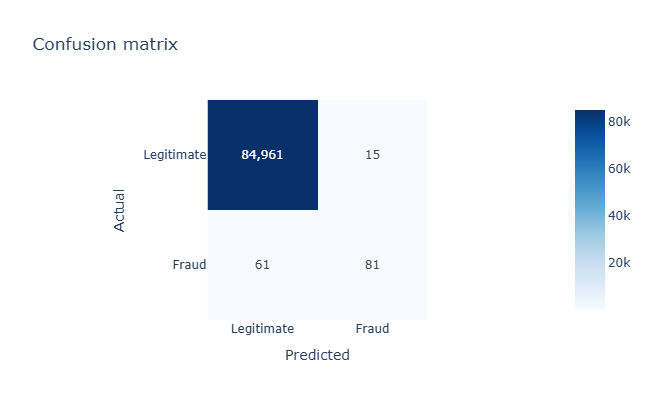

In [7]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train, y_train)
y_pred = log_reg.predict(X_test)

print(f"Train accuracy: {log_reg.score(X_train, y_train):.4%}")
print(f"Test accuracy:  {accuracy_score(y_test, y_pred):.4%}")
print(f"Baseline (always legit): {1 - y_test.mean():.4%}")
print(f"ROC-AUC: {roc_auc_score(y_test, log_reg.predict_proba(X_test)[:, 1]):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["Legitimate", "Fraud"], digits=4))

cm = confusion_matrix(y_test, y_pred)
fig = px.imshow(cm, text_auto=",", x=["Legitimate", "Fraud"], y=["Legitimate", "Fraud"], color_continuous_scale="Blues",
                labels=dict(x="Predicted", y="Actual"), title="Confusion matrix")
fig.update_layout(height=400, width=480)
fig.show()

**Test accuracy is 99.91%** with ROC-AUC of 0.965, and train/test accuracy are nearly identical, so no overfitting. But looking at the fraud class, the model catches only **81 of 142** frauds (recall ≈ 57%), even though its fraud flags are usually correct (precision ≈ 84%, 15 false alarms). With so few fraud examples, the model leans towards predicting "legitimate".

## A5. Handling the imbalance

`class_weight="balanced"` gives fraud cases more weight during training so the model pays more attention to them.

In [8]:
log_reg_bal = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
log_reg_bal.fit(X_train, y_train)
y_pred_bal = log_reg_bal.predict(X_test)

pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, p) for p in (y_pred, y_pred_bal)],
    "Precision": [precision_score(y_test, p) for p in (y_pred, y_pred_bal)],
    "Recall": [recall_score(y_test, p) for p in (y_pred, y_pred_bal)],
    "F1": [f1_score(y_test, p) for p in (y_pred, y_pred_bal)],
    "Frauds caught": [confusion_matrix(y_test, p)[1, 1] for p in (y_pred, y_pred_bal)],
    "False alarms": [confusion_matrix(y_test, p)[0, 1] for p in (y_pred, y_pred_bal)],
}, index=["Standard", "Balanced"]).round(4)

,Accuracy,Precision,Recall,F1,Frauds caught,False alarms
Standard,0.9991,0.8438,0.5704,0.6807,81,15
Balanced,0.9733,0.0529,0.8873,0.0998,126,2257


The balanced model drops to 97.33% accuracy but catches **126 of 142 frauds (89% recall)**, at the cost of ~2,257 false alarms. For a bank, missing fraud is usually more costly than reviewing a flagged transaction, so the balanced model is the more practical one.

## Conclusion
- 1,081 duplicates removed; fraud is only 0.17% of the data.
- Logistic regression reached **99.91% test accuracy**, but that is only slightly above the 99.83% baseline.
- Recall on fraud is the more useful measure: 57% standard vs **89% with class weighting**.